# 01. Python for atoms

- Teaches the small part of Python that every later notebook in this course uses
- Every example uses atoms, energies, forces or distances as its data, so nothing is abstract
- Before you start: module 00 finished, the `mlip-mace` environment active, and Jupyter Lab running
    - The kernel shown at the top right of this notebook is "Python 3 (ipykernel)", the Python of that environment
- After this you can read a code cell in modules 02 to 10 and the capstone, change a value in it, and run it again

## 0. The setup cell

- Run this cell first, every time you open the notebook
- An `import` brings code that someone else wrote into this notebook
    - `from pathlib import Path` takes the `Path` tool out of `pathlib`
    - `pathlib` comes with Python: it is always there, and so are `json`, `subprocess` and `sys`
    - `numpy`, `pandas`, `matplotlib` and `ase` do not come with Python; module 00 installed
      them into the `mlip-mace` environment
    - Either way, an `import` is what makes the code available in this notebook
- `WORK` is the folder this notebook writes its own files into
    - `mkdir(exist_ok=True)` creates the folder, and does nothing if it is already there
    - The folder sits inside this module folder and is not saved to the repository
- `STRUCTURES` points at the shared structure files, two folder levels up
    - `..` means the folder above the current one
- The section on files and folders, further down, comes back to paths in detail

In [1]:
from pathlib import Path

WORK = Path("work")
WORK.mkdir(exist_ok=True)
STRUCTURES = Path("../../structures")

print("Folder this notebook writes into")
print(WORK)

Folder this notebook writes into
work


## 1. Numbers, text and variables

- A variable is a name for a value
    - `energy_slab = -161.784` stores the value on the right under the name on the left
    - Using the name later gives the value back
    - A name can be reused, and the new value replaces the old one
- Three kinds of value appear in every later notebook
    - `int`: a whole number, such as a number of atoms
    - `float`: a number with a decimal point, such as an energy in eV
    - `str`: text between quotes, such as a chemical symbol
- Python knows nothing about units, so the unit lives in the name or in a comment
    - Energies in this course are in eV, distances in Å, forces in eV/Å
    - A comment starts with `#`, and Python ignores the rest of that line
- `type(x)` reports which kind of value `x` holds
    - It prints as `<class 'float'>`, which means "this is a float"
- The numbers below describe a clean Pt(111) slab of 27 atoms, the structure used from module 04 on

In [2]:
energy_slab = -161.784        # eV, clean Pt(111) slab
lattice_constant = 3.92       # Å, face-centred cubic Pt
element = "Pt"
n_atoms = 27

print("Clean slab energy (eV)")
print(energy_slab)
print("Lattice constant (Å)")
print(lattice_constant)
print("Element")
print(element)
print("Number of atoms")
print(n_atoms)

print()
print("Type of energy_slab")
print(type(energy_slab))
print("Type of n_atoms")
print(type(n_atoms))
print("Type of element")
print(type(element))

print()
print("Energy per atom (eV)")
print(round(energy_slab / n_atoms, 3))

Clean slab energy (eV)
-161.784
Lattice constant (Å)
3.92
Element
Pt
Number of atoms
27

Type of energy_slab
<class 'float'>
Type of n_atoms
<class 'int'>
Type of element
<class 'str'>

Energy per atom (eV)
-5.992


## 2. Lists and loops

- A list holds several values in a fixed order, written between square brackets
    - `sites[0]` is the first item, because Python counts from 0 and not from 1
    - `sites[-1]` is the last item
    - `len(sites)` is how many items the list holds
- The two lists below are parallel: item `i` of one belongs with item `i` of the other
    - Adsorption energy of one O atom on Pt(111), one value per adsorption site
    - Referenced to a free O atom, which is why the values are near -4 eV
    - The same reference is used again in the dictionary and the function below
- A `for` loop runs the same lines once for every item of a list
    - The indented lines under the `for` line are the ones that repeat
    - The indentation is four spaces, and Python uses it where other languages use brackets
- `enumerate(sites)` hands out the position and the item together, so both are available inside the loop
- Text is joined with `+`, and `str(i)` turns a number into text so that it can be joined
- `min(energies)` is the smallest value, and `energies.index(...)` says where that value sits
    - The most stable site is the one with the most negative adsorption energy

In [3]:
sites = ["ontop", "bridge", "fcc", "hcp"]
energies = [-3.42, -4.05, -4.21, -4.11]      # eV, one O atom on Pt(111)

print("Number of sites")
print(len(sites))
print("First site in the list")
print(sites[0])
print("Last site in the list")
print(sites[-1])

print()
for i, site in enumerate(sites):
    print("Adsorption energy, site " + str(i) + ", " + site + " (eV)")
    print(energies[i])

print()
print("Lowest adsorption energy (eV)")
print(min(energies))
print("Site holding that energy")
print(sites[energies.index(min(energies))])

Number of sites
4
First site in the list
ontop
Last site in the list
hcp

Adsorption energy, site 0, ontop (eV)
-3.42
Adsorption energy, site 1, bridge (eV)
-4.05
Adsorption energy, site 2, fcc (eV)
-4.21
Adsorption energy, site 3, hcp (eV)
-4.11

Lowest adsorption energy (eV)
-4.21
Site holding that energy
fcc


## 3. Dictionaries

- A dictionary maps a key to a value, written between curly brackets
    - Here the key is the name of the adsorbate and the value is its adsorption energy in eV
    - A list is reached by position, a dictionary by name
- Same reference as the list of site energies above: a free O atom, a free OH radical, a free OOH radical
    - The `O` entry is the fcc value of that list, rounded to one decimal
- `e_ads["O"]` reads one value out
    - A key that is not there raises a `KeyError`, which the section on errors shows on purpose
    - `"O" in e_ads` asks first, and answers `True` or `False`, the two values Python uses for yes and no
    - `e_ads.get("H", 0.0)` reads the key if it is there and gives `0.0` if it is not
- `e_ads.items()` hands out the key and the value together, one pair per turn of the loop
- Adding a key is one line: `e_ads["H"] = -2.6`

In [4]:
e_ads = {"O": -4.2, "OH": -2.1, "OOH": -1.1}      # eV, on Pt(111)

print("Number of adsorbates in the dictionary")
print(len(e_ads))
print("Adsorption energy of O (eV)")
print(e_ads["O"])

print()
print("Is OH in the dictionary")
print("OH" in e_ads)
print("Is H in the dictionary")
print("H" in e_ads)
print("Adsorption energy of H when the key is missing, default used (eV)")
print(e_ads.get("H", 0.0))

print()
for name, value in e_ads.items():
    print("Adsorption energy, " + name + " (eV)")
    print(value)

print()
print("Most negative adsorption energy in the dictionary (eV)")
print(min(e_ads.values()))

Number of adsorbates in the dictionary
3
Adsorption energy of O (eV)
-4.2

Is OH in the dictionary
True
Is H in the dictionary
False
Adsorption energy of H when the key is missing, default used (eV)
0.0

Adsorption energy, O (eV)
-4.2
Adsorption energy, OH (eV)
-2.1
Adsorption energy, OOH (eV)
-1.1

Most negative adsorption energy in the dictionary (eV)
-4.2


## 4. Functions

- A function is a named block of code that takes values in and gives one value back
    - `def` starts the definition, and the indented lines under it are the body
    - The names in brackets are the arguments: the values the function needs to do its work
    - `return` hands the result back to the line that called the function
- Writing a formula once, inside a function, keeps every later use of it identical
- The first text in the body is the docstring, written between triple quotes
    - It says what the function returns and in which unit
    - `help(adsorption_energy)` prints it back at any time
- The formula, with every term taken from the same model and the same settings
    - `E_ads = E(slab + adsorbate) − E(clean slab) − E(reference)`
    - The reference here is one free O atom, as in the list and the dictionary above
    - A negative value means the adsorbate is bound to the surface
- The call below reproduces the fcc value of the list of site energies above

In [5]:
def adsorption_energy(e_total, e_clean, e_ref):
    """Adsorption energy in eV.

    e_total: energy of the slab with the adsorbate on it (eV)
    e_clean: energy of the same slab without the adsorbate (eV)
    e_ref: energy of the reference species, one free atom or one free molecule (eV)
    """
    return e_total - e_clean - e_ref


e_slab_with_o = -170.944      # eV, Pt(111) slab with one O atom on an fcc site
e_clean_slab = -161.784       # eV, the same slab, clean
e_free_o = -4.950             # eV, one free O atom

e_o_fcc = adsorption_energy(e_slab_with_o, e_clean_slab, e_free_o)

print("Adsorption energy of O on the fcc site (eV)")
print(round(e_o_fcc, 3))
print("Value listed for the fcc site in the list of site energies (eV)")
print(energies[2])

Adsorption energy of O on the fcc site (eV)
-4.21
Value listed for the fcc site in the list of site energies (eV)
-4.21


## 5. NumPy arrays

- NumPy is the package that handles numbers in bulk
    - `import numpy as np` brings it in under the short name `np`
    - Every later notebook uses `np` for positions, energies and forces
- An array is a grid of numbers of one kind, held in a single object
    - Atomic positions are an array of shape `(N, 3)`: one row per atom, three columns for x, y and z
    - `positions.shape` reports the number of rows and the number of columns
    - The unit is Å, as everywhere in this course
- A slice takes part of an array
    - `positions[-1]` is the last row, one atom
    - `positions[:-1]` is every row except the last one
- Arithmetic acts on the whole array at once, with no loop
    - `pt_positions - o_position` subtracts the same three numbers from every row
- `np.linalg.norm(v, axis=1)` is the length of each row vector, which turns those differences into distances
    - `axis=1` means "along each row"
- `np.argmin(d)` gives the position of the smallest value, not the value itself
    - `d[np.argmin(d)]` is that smallest value
- `np.round(d, 3)` rounds every number of an array to three decimals, for printing only
- The five atoms below are four Pt atoms of a surface plus one O atom sitting above them
    - The Pt-Pt distance is the nearest-neighbour distance of face-centred cubic Pt, `3.92 / sqrt(2)`, about 2.772 Å
    - The O atom is off the ideal site, so the four distances are all different

In [6]:
import numpy as np

positions = np.array([
    [0.000, 0.000, 0.000],      # Pt
    [2.772, 0.000, 0.000],      # Pt
    [1.386, 2.400, 0.000],      # Pt
    [4.158, 2.400, 0.000],      # Pt
    [1.500, 0.900, 1.281],      # O, above the surface
])

o_position = positions[-1]
pt_positions = positions[:-1]
distances = np.linalg.norm(pt_positions - o_position, axis=1)
nearest = int(np.argmin(distances))

print("Shape of the positions array (rows, columns)")
print(positions.shape)
print("Number of atoms")
print(positions.shape[0])

print()
print("Position of the O atom (Å)")
print(o_position)
print("Distance from the O atom to each Pt atom (Å)")
print(np.round(distances, 3))

print()
print("Index of the nearest Pt atom")
print(nearest)
print("Shortest O to Pt distance (Å)")
print(round(float(distances[nearest]), 3))

Shape of the positions array (rows, columns)
(5, 3)
Number of atoms
5

Position of the O atom (Å)
[1.5   0.9   1.281]
Distance from the O atom to each Pt atom (Å)
[2.168 2.017 1.976 3.31 ]

Index of the nearest Pt atom
2
Shortest O to Pt distance (Å)
1.976


## 6. Reading a table with pandas

- pandas reads and writes tables, and the table it holds in memory is called a DataFrame
    - `import pandas as pd` is the usual short name
    - A DataFrame has named columns and numbered rows
- A CSV file is plain text: one row per line, values separated by commas
    - The first line holds the column names
    - The optimizers used from module 06 on can write their history in this form
- The cell below first writes a small table to `work/relaxation.csv`, then reads it back
    - The numbers imitate a geometry optimization of the clean Pt(111) slab used at the start of this notebook
    - `step` is the optimizer step, `energy` is in eV, `fmax` is the largest force on any atom in eV/Å
    - The energy settles on that same clean slab energy, and `fmax` falls towards zero
    - A real optimization stops when `fmax` drops below the threshold chosen for the project
- Making the three columns, one line each
    - `np` needs no `import` here, because the array section above already imported it
    - `np.arange(12)` makes the whole numbers 0 to 11, one per optimizer step
    - `np.exp(x)` is the exponential function, which is what makes both columns fall and flatten
    - `np.round(values, 3)` rounds to three decimals, as in the array section above
- Writing the table, then reading it back
    - `pd.DataFrame({...})` builds a table out of a dictionary: each key becomes a column name
    - `table.to_csv(path, index=False)` writes it as text, and `index=False` leaves out the row numbers
    - `pd.read_csv(path)` loads the file back into a DataFrame
- Reading values out of a DataFrame
    - `len(df)` is the number of rows, and `df.columns` is the list of column names
    - `df.head()` is the first five rows
    - `df["fmax"]` is one column, and `df["fmax"].min()` is its smallest value
    - `df.min()` without a column name gives the smallest value of every column at once
    - `df.min()` reports `step` as well, because `step` is a column like the others
    - `df.to_string()` prints a table as aligned text, which is how every table in this course is printed

In [7]:
import pandas as pd

step = np.arange(12)
fmax = np.round(0.85 * np.exp(-0.32 * step), 3)
energy = np.round(-161.784 + 0.740 * np.exp(-0.55 * step), 3)

table = pd.DataFrame({"step": step, "energy": energy, "fmax": fmax})
csv_path = WORK / "relaxation.csv"
table.to_csv(csv_path, index=False)

df = pd.read_csv(csv_path)

print("Number of rows")
print(len(df))
print("Column names")
print(list(df.columns))

print()
print("First five rows")
print(df.head().to_string(index=False))

print()
print("Smallest value in each column")
print(df.min().to_string())

print()
print("Lowest energy in the table (eV)")
print(float(df["energy"].min()))
print("Lowest max force in the table (eV/Å)")
print(float(df["fmax"].min()))

Number of rows
12
Column names
['step', 'energy', 'fmax']

First five rows
 step   energy  fmax
    0 -161.044 0.850
    1 -161.357 0.617
    2 -161.538 0.448
    3 -161.642 0.325
    4 -161.702 0.236

Smallest value in each column
step        0.000
energy   -161.782
fmax        0.025

Lowest energy in the table (eV)
-161.782
Lowest max force in the table (eV/Å)
0.025


## 7. One plot

- matplotlib draws every figure in this course
    - `import matplotlib.pyplot as plt` is the usual short name
    - `plt.show()` at the end tells matplotlib the figure is finished
- A DataFrame can plot itself: `df.plot(x="step", y="fmax", ...)` draws one column against another
- The house style for figures in this course
    - Small square panel, `figsize=(3, 3)`
    - Black line, no colour, no grid, no style sheet
    - Axis labels always carry the unit in brackets
    - A thin dashed line marks a reference value, here zero force
    - No title, because the markdown cell above says what the figure shows
- In the plot:
    - `fmax` falls fast over the first steps and then flattens
    - That flat tail is the normal shape of a relaxation approaching its minimum
    - The dashed line at zero is the value the optimizer drives the force towards
    - The curve never reaches zero, which is why a threshold is needed to stop the run

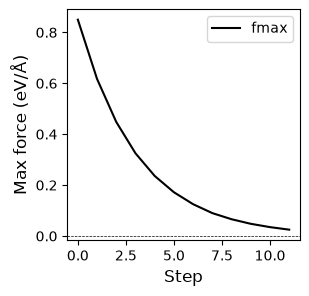

In [8]:
import matplotlib.pyplot as plt

df.plot(x="step", y="fmax", linestyle="-", color="k", figsize=(3, 3))
plt.xlabel("Step", fontsize=12)
plt.ylabel("Max force (eV/Å)", fontsize=12)
plt.axhline(0, color="k", linestyle="--", linewidth=0.5)

plt.show()

## 8. Files and folders

- A path is the address of a file or of a folder
    - `Path("work")` is a folder next to this notebook
    - `Path` comes from `pathlib`, imported in the setup cell
- Paths are joined with a slash, and Python writes the macOS, Linux or Windows spelling for you
    - `WORK / "relaxation.csv"` is the file written by the pandas section above
- `path.exists()` answers `True` or `False`, and is worth asking before reading a file
- `path.name` is the file name on its own, without the folders above it
- `folder.glob("*.csv")` lists every file in that folder whose name ends in `.csv`
    - `*` stands for any text, of any length
    - `sorted(...)` puts the result in alphabetical order, so that a second run prints the same order
- A relative path is read from the folder the notebook file sits in
    - `work` is therefore this module's own `work` folder, wherever Jupyter Lab was started from
    - `STRUCTURES` is such a path: two levels up, then into `structures`

In [9]:
print("Path of the table written by the pandas section")
print(csv_path)
print("Does that file exist")
print(csv_path.exists())
print("File name on its own")
print(csv_path.name)

print()
print("CSV files in the work folder")
for path in sorted(WORK.glob("*.csv")):
    print(path.name)

print()
print("Does the shared structures folder exist")
print(STRUCTURES.exists())
print("Number of VASP structure files in it")
print(len(list(STRUCTURES.glob("*.vasp"))))

Path of the table written by the pandas section
work/relaxation.csv
Does that file exist
True
File name on its own
relaxation.csv

CSV files in the work folder
relaxation.csv

Does the shared structures folder exist
True
Number of VASP structure files in it
3


## 9. Errors you will see

- An error stops the cell and prints a traceback, a block of red text under the cell
    - Read it from the bottom: the last line names the error and gives the message
    - The lines above show which line of which file raised it
- The cell below raises three common errors on purpose
    - Each one is caught, so this notebook keeps running instead of stopping here
    - `try:` runs the risky lines, and `except SomeError as error:` runs only when that error happened
    - Your own cells will not have the `try`, so you will see the traceback instead of these two lines
- The three errors, and what to check first
    - `KeyError`: the key is not in the dictionary, so check the spelling and the upper case
    - `FileNotFoundError`: the file is not where the code looked, so check the path and whether the cell that writes it was run
    - `ImportError`: the package is not installed in the environment this notebook runs in, so check
      that the terminal prompt shows `(mlip-mace)` and that the kernel at the top right of the
      notebook is "Python 3 (ipykernel)"
- An error message is information, not a failure
    - Copy its last line into the message you send your supervisor, together with the command you ran

In [10]:
try:
    value = e_ads["H"]
except KeyError as error:
    print("KeyError, the key is not in the dictionary")
    print(error)

print()
try:
    text = (WORK / "does_not_exist.csv").read_text()
except FileNotFoundError as error:
    print("FileNotFoundError, the file is not where the code looked")
    print(error)

print()
try:
    import package_that_is_not_installed
except ImportError as error:
    print("ImportError, the package is not installed in this environment")
    print(error)

KeyError, the key is not in the dictionary
'H'

FileNotFoundError, the file is not where the code looked
[Errno 2] No such file or directory: 'work/does_not_exist.csv'

ImportError, the package is not installed in this environment
No module named 'package_that_is_not_installed'


## Check yourself

1. The four site names are in one list and their four adsorption energies in another list, in the same
   order. Which single line gives the name of the most stable site?
2. `df` holds the table read from `work/relaxation.csv`. Which expression gives the smallest value of
   the `fmax` column, and in which unit is that value?
3. A cell stops with `KeyError: 'OOH'` on the line `value = e_ads["OOH"]`. What went wrong, and what
   do you check first?

<details>
<summary>Answers</summary>

- `sites[energies.index(min(energies))]`: `min` gives the smallest energy, `index` says at which
  position it sits, and that position is read out of the parallel list of names
- `df["fmax"].min()`, in eV/Å; the unit comes from the column, not from pandas, which knows nothing
  about units
- The dictionary `e_ads` has no key `"OOH"`; check the spelling and the upper case first, then print
  `e_ads.keys()` to see which keys the dictionary actually has

</details>